# Methodology 


- for any phase where signal stays constant. 
    - print(np.full(3,7))
- for any phase signal where value goes up or down. 
    - print(np.linspace(0,10))
- glue these arrays together end to end. 
    - print(np.concatenate([np.full(3,7), np.linspace(0,10,5)]))
- Like range(4) as an array. for time count. If current has 300 values for example, we want 0 to 299. 
    - print(np.arange(4))

# 5 phases for charging decided: 
    - Waiting: plugged in but not yet charging. Current is 0, held constant. 
    - Ramp: current rises from 0 to 16A. 
    - Plateau: charging at full current, held constant at 16A, back to 0. 
    - Taper: the battery is nearly full, so current falls from 16 back to 0. 
    - Done: charging finished but still pluggedd in. current is 0. 


In [1]:
# FIRST FUNCTION: 
# simulate_sessions
# inputs: random generator
# outputs: dataframe with columns time, current, voltage, power, status_charging and pilot_status
# Phase_lenght and values: write down the numbers that I want (waiting 30-60 s, max current 16A, max power 4kw etc)

import numpy as np
import pandas as pd

def simulate_sessions(): 
    # plugged in but not yet charging. 
    wait_len = 5 # seconds
    
    # current rises from min_current to max_current    
    ramp_len = 30 # seconds 
    
    # charging max current --> constant.
    plateau_len = 60 # seconds 

    # battery nearly full, max_current drops to min_current. 
    taper_len = 15 # seconds
    
    # charged but still plugged. 
    done_len = 5 # seconds 
    
    # Current
    max_current = 16 # Amperes
    min_current = 0 # Amperes
    
    # Voltage 
    nominal_voltage = 230 # Volts 
    min_voltage = 0 # Volts
    
    ##### CURRENT PHASES #####
    
    current_waiting = np.full(wait_len,min_current) 
    current_ramp = np.linspace(min_current, max_current, ramp_len) 
    current_plateau = np.full(plateau_len, max_current)   
    current_taper = np.linspace(max_current,min_current, taper_len) 
    current_done = np.full(done_len,min_current) 
    
    # concatenating into an array the current from the charging session. 
    current_concatenated = np.concatenate([
        current_waiting, 
        current_ramp, 
        current_plateau, 
        current_taper, 
        current_done
        ]) 
    
    ##### TIME PHASES #####
    
    # time column stays correct automatically when I change a phase length.
    time_session = np.arange(len(current_concatenated))
    
    ##### PILOT STATUS #####
    

    # Based on IEC 61851
    # ID = B --> “vehicle plug connected, not ready to charge"
    # ID = C --> “vehicle plug connected, ready, charging requested.”
    
    pilot_waiting = np.full(wait_len, "B")
    pilot_ramp = np.full(ramp_len, "C")
    pilot_plateau = np.full(plateau_len, "C")
    pilot_taper= np.full(taper_len, "C")
    pilot_done = np.full(done_len, "B")
    pilot_concatenated = np.concatenate([
        pilot_waiting, 
        pilot_ramp, 
        pilot_plateau, 
        pilot_taper, 
        pilot_done
        ])
    
    ##### VOLTAGE #####
    
    voltage_waiting = np.full(wait_len, min_voltage)
    voltage_ramp = np.full(ramp_len, nominal_voltage)
    voltage_plateau = np.full(plateau_len, nominal_voltage)
    voltage_taper = np.full(taper_len, nominal_voltage)
    voltage_done = np.full(done_len, min_voltage)
    voltage_concatenated = np.concatenate([voltage_waiting, voltage_ramp, voltage_plateau, voltage_taper, voltage_done])
    
    
    ##### CHARGING STATUS #####
    
    # Idle --> no current flowing to the battery (AC or DC)
    # Charging --> current flowing to the battery
    # Complete --> no current flowing to the battery due to battery being full of charge. 
    
    sc_waiting = np.full(wait_len, "idle")
    sc_ramp = np.full(ramp_len, "charging")
    sc_plateau = np.full(plateau_len, "charging")
    sc_taper = np.full(taper_len, "charging")
    sc_done = np.full(done_len, "complete")
    
    sc_concatenated = np.concatenate([sc_waiting, sc_ramp, sc_plateau, sc_taper, sc_done])
    
    ##### POWER  #####
    
    # Power = Voltage x current 
    power_concatenated = voltage_concatenated * current_concatenated
    
    # Dataframe object creation 
    df = pd.DataFrame({
        "current": current_concatenated, 
        "time": time_session, 
        "pilot_status": pilot_concatenated, 
        "status_charging": sc_concatenated, 
        "Voltage": voltage_concatenated, 
        "power": power_concatenated
    })
    
    return df



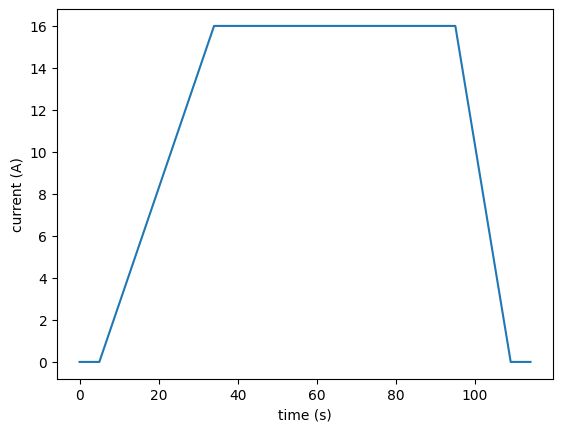

In [2]:
import matplotlib.pyplot as plt 

current = simulate_sessions()

plt.plot(current["current"])
plt.xlabel("time (s)")
plt.ylabel("current (A)")
plt.show()

In [3]:
# print Dataframe
print(current.head())

print(current.tail())

   current  time pilot_status status_charging  Voltage  power
0      0.0     0            B            idle        0    0.0
1      0.0     1            B            idle        0    0.0
2      0.0     2            B            idle        0    0.0
3      0.0     3            B            idle        0    0.0
4      0.0     4            B            idle        0    0.0
     current  time pilot_status status_charging  Voltage  power
110      0.0   110            B        complete        0    0.0
111      0.0   111            B        complete        0    0.0
112      0.0   112            B        complete        0    0.0
113      0.0   113            B        complete        0    0.0
114      0.0   114            B        complete        0    0.0


In [4]:
# SESSION TYPES: 

"""  
    - Power_fault (supply fails during charging): supply drops during the plateau, current and voltage go to 0, session ends in error.

    - Pilot fault (communication problem): pilot flaps B/C a few times (current and voltage drop to 0 each time it’s B), then gives up in error.
    
    - thermal_derating: mid-plateau, current steps down (16 → 8 A) and charging finishes at reduced current.

"""

'  \n    - Power_fault (supply fails during charging): supply drops during the plateau, current and voltage go to 0, session ends in error.\n\n    - Pilot fault (communication problem): pilot flaps B/C a few times (current and voltage drop to 0 each time it’s B), then gives up in error.\n    \n    - thermal_derating: mid-plateau, current steps down (16 → 8 A) and charging finishes at reduced current.\n\n'

In [5]:
# Convert to a helper so that we don't need to hardcode everything for the other session signals. 
# Call the helper once per phase so that it returns all signals with values for that phase. 
def make_per_phase (length, current_start, current_end, voltage, pilot_status, status_charging): 
    current_var = np.linspace(current_start, current_end, length)
    voltage_var = np.full(length, voltage)
    pilot_var = np.full(length, pilot_status)
    status_charging_var = np.full(length, status_charging)
    power_var = current_var * voltage_var
    
    df = pd.DataFrame({
        "current": current_var, 
        "voltage": voltage_var,
        "pilot_status": pilot_var, 
        "status_charging": status_charging_var, 
        "power": power_var
        
    })
    return df



In [ ]:
# testing 
phase = make_per_phase(5, 16, 16, 230, "C", "charging")
print(phase)

assert len(phase) == 5
assert phase["current"].iloc[0] == 16
assert phase["power"].iloc[-1] == 3680

ramp_test = make_per_phase(5, 0, 16, 230, "C", "charging")
print(ramp_test)

assert len(ramp_test) == 5
# check if first value of current is 0 
assert ramp_test["current"].iloc[0] == 0.0
# check if last value of current is 16 A
assert ramp_test["current"].iloc[-1] == 16
# check if first value of power is 0
assert ramp_test["power"].iloc[0] == 0
# check if last value of power is 230
assert ramp_test["power"].iloc[-1] == 3680

   current  voltage pilot_status status_charging   power
0     16.0      230            C        charging  3680.0
1     16.0      230            C        charging  3680.0
2     16.0      230            C        charging  3680.0
3     16.0      230            C        charging  3680.0
4     16.0      230            C        charging  3680.0
   current  voltage pilot_status status_charging   power
0      0.0      230            B        charging     0.0
1      4.0      230            B        charging   920.0
2      8.0      230            B        charging  1840.0
3     12.0      230            B        charging  2760.0
4     16.0      230            B        charging  3680.0


In [44]:
# Rebuild the power fault session 
def simulate_sessions(session_type): 
    if session_type == "power_fault": 
        phases = [
            make_per_phase(5, 0, 0, 0, "B", "idle"),          # waiting phase
            make_per_phase(30, 0, 16, 230, "C", "charging"),  # ramp up phase
            make_per_phase(60, 16, 16, 230, "C", "charging"), # plateau phase 
            make_per_phase(5, 0, 0, 0, "E", "error")   # fault phase
        ]
    elif session_type == "pilot_fault":
        phases = [
            make_per_phase(5, 0, 0, 0, "B", "idle"),             # waiting
            make_per_phase(30, 0, 16, 230, "C", "charging"),     # ramp up
            make_per_phase(20, 16, 16, 230, "C", "charging"),    # plateau
            make_per_phase(3, 0, 0, 0, "B", "interrupted"),      # flap off
            make_per_phase(10, 16, 16, 230, "C", "charging"),    # flap on
            make_per_phase(3, 0, 0, 0, "B", "interrupted"),      # flap off
            make_per_phase(10, 16, 16, 230, "C", "charging"),    # flap on
            make_per_phase(3, 0, 0, 0, "B", "interrupted"),      # flap off
            make_per_phase(5, 0, 0, 0, "F", "error"),            # fault
        ]
    elif session_type == "thermal_derating":
        phases = [
            make_per_phase(5, 0, 0, 0, "B", "idle"),             # waiting
            make_per_phase(30, 0, 16, 230, "C", "charging"),     # ramp up
            make_per_phase(40, 16, 16, 230, "C", "charging"),    # plateau
            make_per_phase(40, 8, 8, 230, "C", "charging"),      # derated
            make_per_phase(10, 8, 0, 230, "C", "charging"),      # taper
            make_per_phase(5, 0, 0, 0, "B", "complete"),         # done
        ]
    else: 
        raise ValueError("wrong session type")
    
    # concatenate all phases from the respective session type. 
    df = pd.concat(phases, ignore_index= True)
    # adding time column after the concat
    df["time"] = np.arange(len(df))
    return df

sessions_reconstruction = simulate_sessions("thermal_derating")
print(sessions_reconstruction)

     current  voltage pilot_status status_charging  power  time
0        0.0        0            B            idle    0.0     0
1        0.0        0            B            idle    0.0     1
2        0.0        0            B            idle    0.0     2
3        0.0        0            B            idle    0.0     3
4        0.0        0            B            idle    0.0     4
..       ...      ...          ...             ...    ...   ...
125      0.0        0            B        complete    0.0   125
126      0.0        0            B        complete    0.0   126
127      0.0        0            B        complete    0.0   127
128      0.0        0            B        complete    0.0   128
129      0.0        0            B        complete    0.0   129

[130 rows x 6 columns]


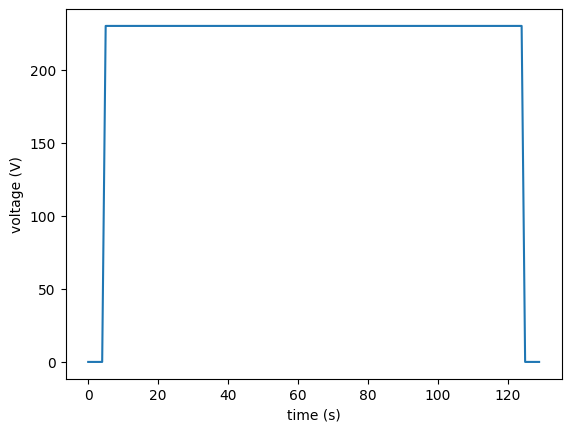

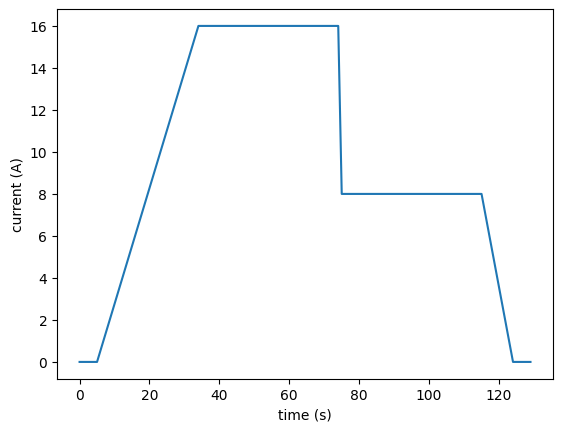

In [45]:
# Plotting the voltage and current behaviors. 
plt.plot(sessions_reconstruction["time"], sessions_reconstruction["voltage"])
plt.xlabel("time (s)")
plt.ylabel("voltage (V)")
plt.show()

plt.plot(sessions_reconstruction["time"], sessions_reconstruction["current"])
plt.xlabel("time (s)")
plt.ylabel("current (A)")
plt.show()

In [47]:
rng = np.random.default_rng(42)
print(rng.integers(3,11))
print(rng.integers(3,11))

3
9
